# PINN لنموذج Belousov–Zhabotinsky الكسري زمنياً (Time-Fractional BZRM)

**الحالة 1 (Case 1):** $d_1=d_2=1,\ \epsilon=\eta=0$ — النظام (4.1) المستخدم في الأشكال 5 و 7 و 8.

$$
{}^{C}_{0}D_t^{\alpha}U = U_{xx} + U - U^2 - \rho\,U V ,\qquad
{}^{C}_{0}D_t^{\alpha}V = V_{xx} - \xi\,U V ,\qquad x\in[-10,10],\ t\in[0,0.5]
$$

**الشروط الابتدائية (4.2):** $U_0=\dfrac{1}{(e^{\sqrt{\xi/6}\,x}+1)^2}$ ، $V_0=\dfrac{(1-\xi)}{\rho}\Big(1-U_0\Big)$ (مكافئة للصيغة المعطاة في الورقة).

**الحل الدقيق عند $\alpha=1$ (4.3)** بصيغة مختصرة مكافئة: $U=\dfrac{1}{(1+z)^2},\quad V=\dfrac{1-\xi}{\rho}\,(1-U),\quad z=e^{\sqrt{\xi/6}\,x-\frac{5\xi}{6}t}$

**الشروط الحدودية (افتراضية):** ديريكليه عند $x=\pm10$: $U(-10)=1,\ U(10)=0,\ V(-10)=0,\ V(10)=(1-\xi)/\rho$.

In [1]:
# ============================ 1) الإعداد والمعاملات ============================
import time, math, os, copy
import numpy as np, pandas as pd
import torch, torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy.special import gamma
import scipy.sparse as sp
from scipy.sparse.linalg import splu

torch.set_default_dtype(torch.float64)          # دقة مضاعفة لاستقرار L-BFGS
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.manual_seed(0); np.random.seed(0)
os.makedirs("figures", exist_ok=True)

# ---- معاملات النموذج (قيم ξ و ρ مُقدَّرة من الرسوم، انظر قائمة الافتراضات) ----
XI, RHO = 3.0, 2.0
D1 = D2 = 1.0
L, T_END = 10.0, 0.5                 # النطاق: x∈[-L,L] ، t∈[0,T_END]
ALPHAS = [0.9, 0.7, 0.5,0.3]        # قيم α في الأشكال 7 و 8 (بالإضافة إلى α=1)

# ---- الشبكة المشتركة للمقارنة (PINN مقابل الطريقة العددية) ----
NX_PLOT, NT = 201, 100               # dx = 0.1 ، dt = 0.005
xs = np.linspace(-L, L, NX_PLOT)
ts = np.linspace(0, T_END, NT + 1)
DT = T_END / NT
T_GRID = torch.tensor(ts, device=device)

# ---- إعدادات التدريب ----
FAST_MODE   = False                  # True = تجربة سريعة للتأكد من عمل الكود
ADAM_ITERS  = 300  if FAST_MODE else 4000
LBFGS_ITERS = 30   if FAST_MODE else 400
NX_COL      = 128  if FAST_MODE else 256     # عدد نقاط x العشوائية في كل تكرار
W_BC        = 10.0                            # وزن خسارة الحدود
print("device:", device)

device: cuda


In [2]:
# ============================ 2) الحل الدقيق (α=1) والشروط الابتدائية/الحدودية ============================
def exact_np(x, t):
    s, c = math.sqrt(XI/6), 5*XI/6
    z = np.exp(s*x - c*t)
    U = 1/(1+z)**2
    V = (1-XI)/RHO*(1-U)
    return U, V

def exact_torch(x, t):
    s, c = math.sqrt(XI/6), 5*XI/6
    z = torch.exp(s*x - c*t)
    U = 1/(1+z)**2
    V = (1-XI)/RHO*(1-U)
    return U, V

def bc_targets(alpha, t):
    """قيم الحدود عند x=-L و x=+L. عند α=1 نستخدم الحل الدقيق، وعند α<1 القيم المقاربة."""
    one, zero = torch.ones_like(t), torch.zeros_like(t)
    if alpha == 1.0:
        Ul, Vl = exact_torch(-L*one, t); Ur, Vr = exact_torch(L*one, t)
    else:
        Ul, Vl, Ur, Vr = one, zero, zero, (1-XI)/RHO*one
    return Ul, Vl, Ur, Vr

# ---- تحقق ذاتي: هل الحل الدقيق يحقق النظام (4.1) عند α=1 بالقيم ξ=3, ρ=2 ؟ ----
def check_exact_residual():
    x = (torch.rand(2000,1)*2-1)*L; t = torch.rand(2000,1)*T_END
    x.requires_grad_(True); t.requires_grad_(True)
    U, V = exact_torch(x, t)
    g = lambda f, v: torch.autograd.grad(f, v, torch.ones_like(f), create_graph=True)[0]
    Ut, Vt = g(U,t), g(V,t); Uxx, Vxx = g(g(U,x),x), g(g(V,x),x)
    r1 = Ut-(D1*Uxx+U-U**2-RHO*U*V); r2 = Vt-(D2*Vxx-XI*U*V)
    print(f"max|R_U|={r1.abs().max():.2e} , max|R_V|={r2.abs().max():.2e}  (يجب أن تكون ≈ 1e-15)")
check_exact_residual()

max|R_U|=1.06e-15 , max|R_V|=1.05e-15  (يجب أن تكون ≈ 1e-15)


In [3]:
# ============================ 3) الطريقة العددية المرجعية: فروق محدودة + مخطط L1 لمشتقة Caputo ============================
def l1_weights(alpha):
    k = np.arange(NT_FD_MAX+1)
    return (k+1)**(1-alpha) - k**(1-alpha)

NT_FD_MAX = 5000

def fd_solver(alpha, nx=401, nt=1000):
    """
    نظام شبه ضمني (IMEX): الانتشار ضمني، التفاعل صريح، ومشتقة Caputo بمخطط L1.
    (c I - Δ) u^{n+1} = c u^n - c Σ_{k=1}^{n} b_k (u^{n+1-k}-u^{n-k}) + f(u^n)
    """
    x = np.linspace(-L, L, nx); dx = x[1]-x[0]; dt = T_END/nt
    c = dt**(-alpha)/gamma(2-alpha); b = l1_weights(alpha)
    main = -2*np.ones(nx); off = np.ones(nx-1)
    Lap = sp.diags([off, main, off], [-1,0,1])/dx**2
    A = (c*sp.identity(nx) - Lap).tolil()
    A[0,:] = 0; A[0,0] = 1; A[-1,:] = 0; A[-1,-1] = 1           # حدود ديريكليه
    lu = splu(A.tocsc())
    U = np.zeros((nx, nt+1)); V = np.zeros((nx, nt+1))
    U[:,0], V[:,0] = exact_np(x, 0.0)
    dU = np.zeros((nx, nt)); dV = np.zeros((nx, nt))
    Vr = (1-XI)/RHO
    for n in range(nt):
        if n > 0:
            hU = dU[:, :n][:, ::-1] @ b[1:n+1]; hV = dV[:, :n][:, ::-1] @ b[1:n+1]
        else:
            hU = hV = 0.0
        u, v = U[:,n], V[:,n]
        rhsU = c*u - c*hU + (u - u**2 - RHO*u*v)
        rhsV = c*v - c*hV + (-XI*u*v)
        tn = (n+1)*dt
        if alpha == 1.0:
            (ul, vl), (ur, vr) = exact_np(-L, tn), exact_np(L, tn)
        else:
            ul, vl, ur, vr = 1.0, 0.0, 0.0, Vr
        rhsU[0], rhsU[-1], rhsV[0], rhsV[-1] = ul, ur, vl, vr
        U[:,n+1], V[:,n+1] = lu.solve(rhsU), lu.solve(rhsV)
        dU[:,n], dV[:,n] = U[:,n+1]-U[:,n], V[:,n+1]-V[:,n]
    return x, np.linspace(0, T_END, nt+1), U, V

def l1_matrix(alpha, nt=NT, dt=DT):
    """مصفوفة تقريب Caputo بمخطط L1 على شبكة PINN الزمنية: (D^α u)_n = Σ_j W[n,j] u_j"""
    c = dt**(-alpha)/gamma(2-alpha); b = l1_weights(alpha)
    W = np.zeros((nt+1, nt+1))
    for n in range(1, nt+1):
        for j in range(1, n+1):
            W[n, j]   += c*b[n-j]
            W[n, j-1] -= c*b[n-j]
    return W

# ---- تحقق: L1 دقيق للدوال الخطية  D^α t = t^{1-α}/Γ(2-α) ----
_a = 0.6; _W = l1_matrix(_a)
print("خطأ مخطط L1 على u=t:", np.abs(_W@ts - ts**(1-_a)/gamma(2-_a))[1:].max())

# ---- حل مرجعي لكل قيم α (مع قياس الزمن) ----
ref, t_fd = {}, {}
for a in [1.0] + ALPHAS:
    t0 = time.time(); xf, tf, Uf, Vf = fd_solver(a); t_fd[a] = time.time()-t0
    ref[a] = (Uf[::2, ::10], Vf[::2, ::10])          # أخذ عينات على نفس شبكة PINN (201×101)
    print(f"α={a}: FD time={t_fd[a]:.2f}s , shape={ref[a][0].shape}")
Xg, Tg = np.meshgrid(xs, ts, indexing="ij")
U_ex, V_ex = exact_np(Xg, Tg)
print("FD(α=1) مقابل الحل الدقيق: max|ΔU| =", np.abs(ref[1.0][0]-U_ex).max())

خطأ مخطط L1 على u=t: 2.6645352591003757e-15
α=1.0: FD time=0.20s , shape=(201, 101)
α=0.9: FD time=0.20s , shape=(201, 101)
α=0.7: FD time=0.19s , shape=(201, 101)
α=0.5: FD time=0.20s , shape=(201, 101)
α=0.3: FD time=0.19s , shape=(201, 101)
FD(α=1) مقابل الحل الدقيق: max|ΔU| = 0.0001609152598500141


In [4]:
# ============================ 4) بناء نموذج PINN ============================
class AdaTanh(nn.Module):
    """دالة تنشيط تكيفية: tanh(a·x) مع a معامل قابل للتعلّم (Jagtap et al.)."""
    def __init__(self): super().__init__(); self.a = nn.Parameter(torch.tensor(1.0))
    def forward(self, x): return torch.tanh(self.a*x)

class PINN(nn.Module):
    """
    MLP كامل الاتصال: (x,t) -> (U,V).
    الشروط الابتدائية مفروضة بشكل صارم (Hard constraint):  U = U0(x) + (t/T)·NN(x,t)
    بذلك لا نحتاج حد خسارة للشروط الابتدائية.
    """
    def __init__(self, hidden=64, depth=4):
        super().__init__()
        layers = [nn.Linear(2, hidden), AdaTanh()]
        for _ in range(depth-1): layers += [nn.Linear(hidden, hidden), AdaTanh()]
        layers.append(nn.Linear(hidden, 2))
        self.net = nn.Sequential(*layers)
        for m in self.net:
            if isinstance(m, nn.Linear): nn.init.xavier_normal_(m.weight); nn.init.zeros_(m.bias)
    def forward(self, x, t):
        out = self.net(torch.cat([x/L, 2*t/T_END-1], dim=1))      # تطبيع المدخلات إلى [-1,1]
        U0, V0 = exact_torch(x, torch.zeros_like(x))              # U0(x), V0(x) من (4.2)
        s = t/T_END
        return U0 + s*out[:, 0:1], V0 + s*out[:, 1:2]

def grad(f, v):
    return torch.autograd.grad(f, v, torch.ones_like(f), create_graph=True)[0]

def losses(model, alpha, x, W):
    """خسارة المعادلة (Residual) + خسارة الحدود. x: (Nx,1) نقاط عشوائية؛ الزمن على الشبكة الكاملة."""
    nx_, nt1 = x.shape[0], NT+1
    xx = x.detach().repeat(1, nt1).reshape(-1, 1).requires_grad_(True)
    tt = T_GRID.view(1, -1).repeat(nx_, 1).reshape(-1, 1)
    if alpha == 1.0: tt = tt.requires_grad_(True)
    U, V = model(xx, tt)
    Uxx, Vxx = grad(grad(U, xx), xx), grad(grad(V, xx), xx)       # المشتقات التلقائية المكانية
    if alpha == 1.0:                                              # α=1 : مشتقة تلقائية في الزمن
        DU, DV = grad(U, tt), grad(V, tt)
    else:                                                         # α<1 : مشتقة Caputo بمخطط L1 (fPINN)
        DU = (U.reshape(nx_, nt1) @ W.T).reshape(-1, 1)
        DV = (V.reshape(nx_, nt1) @ W.T).reshape(-1, 1)
    rU = DU - (D1*Uxx + U - U**2 - RHO*U*V)
    rV = DV - (D2*Vxx - XI*U*V)
    sl = lambda r: r.reshape(nx_, nt1)[:, 1:]                     # نستثني t=0 (محقق بالبناء)
    loss_pde = (sl(rU)**2).mean() + (sl(rV)**2).mean()
    tb = T_GRID.view(-1, 1)
    Ul_t, Vl_t, Ur_t, Vr_t = bc_targets(alpha, tb)
    Ul, Vl = model(torch.full_like(tb, -L), tb); Ur, Vr = model(torch.full_like(tb, L), tb)
    loss_bc = ((Ul-Ul_t)**2).mean()+((Vl-Vl_t)**2).mean()+((Ur-Ur_t)**2).mean()+((Vr-Vr_t)**2).mean()
    return loss_pde + W_BC*loss_bc, loss_pde, loss_bc

In [5]:
# ============================ 5) التدريب: Adam (+ جدولة LR) ثم L-BFGS ============================
X_VAL = torch.linspace(-L, L, 400, device=device).view(-1, 1)     # نقاط تحقق ثابتة لاختيار أفضل نموذج

def train_pinn(alpha, model=None, adam_iters=ADAM_ITERS, lbfgs_iters=LBFGS_ITERS, lr=1e-3, verbose=True):
    model = model if model is not None else PINN().to(device)
    W = torch.tensor(l1_matrix(alpha), device=device) if alpha != 1.0 else None
    hist = {"total": [], "pde": [], "bc": [], "stage": []}
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=adam_iters, eta_min=1e-5)
    t0 = time.time()
    # ---------- المرحلة 1: Adam مع إعادة أخذ عينات عشوائية لنقاط x (Collocation) ----------
    for it in range(adam_iters):
        x = (torch.rand(NX_COL, 1, device=device)*2-1)*L
        loss, lp, lb = losses(model, alpha, x, W)
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        hist["total"].append(loss.item()); hist["pde"].append(lp.item()); hist["bc"].append(lb.item()); hist["stage"].append(0)
        if verbose and it % 500 == 0: print(f"  [Adam {it:5d}] loss={loss.item():.3e} pde={lp.item():.3e} bc={lb.item():.3e}")
    adam_state = {k: v.clone() for k, v in model.state_dict().items()}
    # ---------- المرحلة 2: L-BFGS على مجموعة نقاط ثابتة ----------
    x_fix = (torch.rand(NX_COL*2, 1, device=device)*2-1)*L
    lbfgs = torch.optim.LBFGS(model.parameters(), lr=1.0, max_iter=lbfgs_iters, max_eval=int(lbfgs_iters*1.25),
                              history_size=50, tolerance_grad=1e-12, tolerance_change=1e-14, line_search_fn="strong_wolfe")
    def closure():
        lbfgs.zero_grad(); loss, lp, lb = losses(model, alpha, x_fix, W); loss.backward()
        hist["total"].append(loss.item()); hist["pde"].append(lp.item()); hist["bc"].append(lb.item()); hist["stage"].append(1)
        return loss
    lbfgs.step(closure)
    # ---------- اختيار أفضل نموذج على نقاط التحقق ----------
    final_state = {k: v.clone() for k, v in model.state_dict().items()}
    def val(state):
        model.load_state_dict(state); return losses(model, alpha, X_VAL, W)[0].item()
    v_adam, v_fin = val(adam_state), val(final_state)
    model.load_state_dict(adam_state if (not np.isfinite(v_fin) or v_adam < v_fin) else final_state)
    train_time = time.time()-t0
    if verbose: print(f"  val(Adam)={v_adam:.3e}  val(L-BFGS)={v_fin:.3e}  | زمن التدريب={train_time:.1f}s")
    return model, hist, train_time

@torch.no_grad()
def predict(model, xs_, ts_):
    X, T = np.meshgrid(xs_, ts_, indexing="ij")
    x = torch.tensor(X.reshape(-1, 1), device=device); t = torch.tensor(T.reshape(-1, 1), device=device)
    U, V = model(x, t)
    return U.cpu().numpy().reshape(X.shape), V.cpu().numpy().reshape(X.shape)

# ---- تدريب α=1 أولاً ثم "نقل التعلم" (warm start) إلى القيم الأصغر ----
models, hists, t_train, pinn, t_inf = {}, {}, {}, {}, {}
prev = None
for a in [1.0] + ALPHAS:
    print(f"\n=== تدريب PINN عند α={a} ===")
    m0 = copy.deepcopy(prev) if prev is not None else None
    models[a], hists[a], t_train[a] = train_pinn(a, model=m0, lr=1e-3 if prev is None else 5e-4)
    t0 = time.time(); pinn[a] = predict(models[a], xs, ts); t_inf[a] = time.time()-t0
    prev = models[a]
    torch.save(models[a].state_dict(), f"figures/best_pinn_alpha_{a}.pt")      # حفظ أفضل نموذج


=== تدريب PINN عند α=1.0 ===
  [Adam     0] loss=4.105e+00 pde=3.092e+00 bc=1.013e-01
  [Adam   500] loss=1.554e-02 pde=1.445e-02 bc=1.092e-04
  [Adam  1000] loss=1.196e-03 pde=9.541e-04 bc=2.416e-05
  [Adam  1500] loss=3.570e-04 pde=3.174e-04 bc=3.964e-06
  [Adam  2000] loss=1.511e-04 pde=1.421e-04 bc=9.051e-07
  [Adam  2500] loss=1.080e-04 pde=1.054e-04 bc=2.622e-07
  [Adam  3000] loss=7.783e-05 pde=7.588e-05 bc=1.949e-07
  [Adam  3500] loss=6.437e-05 pde=6.271e-05 bc=1.666e-07
  val(Adam)=6.067e-05  val(L-BFGS)=2.154e-06  | زمن التدريب=1448.8s

=== تدريب PINN عند α=0.9 ===
  [Adam     0] loss=2.880e-03 pde=2.859e-03 bc=2.086e-06
  [Adam   500] loss=2.496e-04 pde=2.379e-04 bc=1.164e-06
  [Adam  1000] loss=2.426e-04 pde=2.215e-04 bc=2.108e-06
  [Adam  1500] loss=1.669e-04 pde=1.605e-04 bc=6.390e-07
  [Adam  2000] loss=1.513e-04 pde=1.433e-04 bc=7.949e-07
  [Adam  2500] loss=1.256e-04 pde=1.186e-04 bc=6.998e-07
  [Adam  3000] loss=9.877e-05 pde=9.225e-05 bc=6.522e-07
  [Adam  3500] lo

In [6]:
# ============================ 6) التقييم: مقاييس الخطأ والزمن ============================
def metrics(P, R):
    e = P - R
    return dict(MSE=np.mean(e**2), MAE=np.mean(np.abs(e)),
                RelL2=np.linalg.norm(e)/np.linalg.norm(R), Corr=np.corrcoef(P.ravel(), R.ravel())[0, 1])

rows = []
for a in [1.0] + ALPHAS:
    for name, k in (("U", 0), ("V", 1)):
        r = dict(alpha=a, var=name, ref="FD-L1"); r.update(metrics(pinn[a][k], ref[a][k])); rows.append(r)
        if a == 1.0:
            r = dict(alpha=a, var=name, ref="Exact"); r.update(metrics(pinn[a][k], (U_ex, V_ex)[k])); rows.append(r)
df_err = pd.DataFrame(rows)
pd.set_option("display.float_format", lambda v: f"{v:.3e}")
display(df_err)

df_time = pd.DataFrame({"alpha": [1.0]+ALPHAS,
                        "PINN train (s)": [t_train[a] for a in [1.0]+ALPHAS],
                        "PINN inference (s)": [t_inf[a] for a in [1.0]+ALPHAS],
                        "FD-L1 solver (s)": [t_fd[a] for a in [1.0]+ALPHAS]})
display(df_time)
df_err.to_csv("figures/error_metrics.csv", index=False); df_time.to_csv("figures/timing.csv", index=False)

,alpha,var,ref,MSE,MAE,RelL2,Corr
0,1.000e+00,U,FD-L1,2.862e-08,1.110e-04,2.626e-04,1.000e+00
1,1.000e+00,U,Exact,2.798e-08,1.091e-04,2.596e-04,1.000e+00
2,1.000e+00,V,FD-L1,3.169e-08,1.245e-04,2.603e-04,1.000e+00
3,1.000e+00,V,Exact,3.038e-08,1.205e-04,2.548e-04,1.000e+00
4,9.000e-01,U,FD-L1,3.289e-07,4.265e-04,8.826e-04,1.000e+00
5,9.000e-01,V,FD-L1,2.693e-07,3.706e-04,7.661e-04,1.000e+00
6,7.000e-01,U,FD-L1,3.785e-06,1.201e-03,2.933e-03,1.000e+00
7,7.000e-01,V,FD-L1,2.986e-06,1.046e-03,2.630e-03,1.000e+00
8,5.000e-01,U,FD-L1,1.767e-05,2.519e-03,6.136e-03,1.000e+00
9,5.000e-01,V,FD-L1,1.757e-05,2.319e-03,6.891e-03,1.000e+00


,alpha,PINN train (s),PINN inference (s),FD-L1 solver (s)
0,1.000e+00,1.449e+03,4.469e-03,2.043e-01
1,9.000e-01,1.089e+03,4.536e-03,1.951e-01
2,7.000e-01,1.088e+03,4.661e-03,1.937e-01
3,5.000e-01,1.089e+03,4.752e-03,1.965e-01
4,3.000e-01,1.088e+03,4.759e-03,1.947e-01


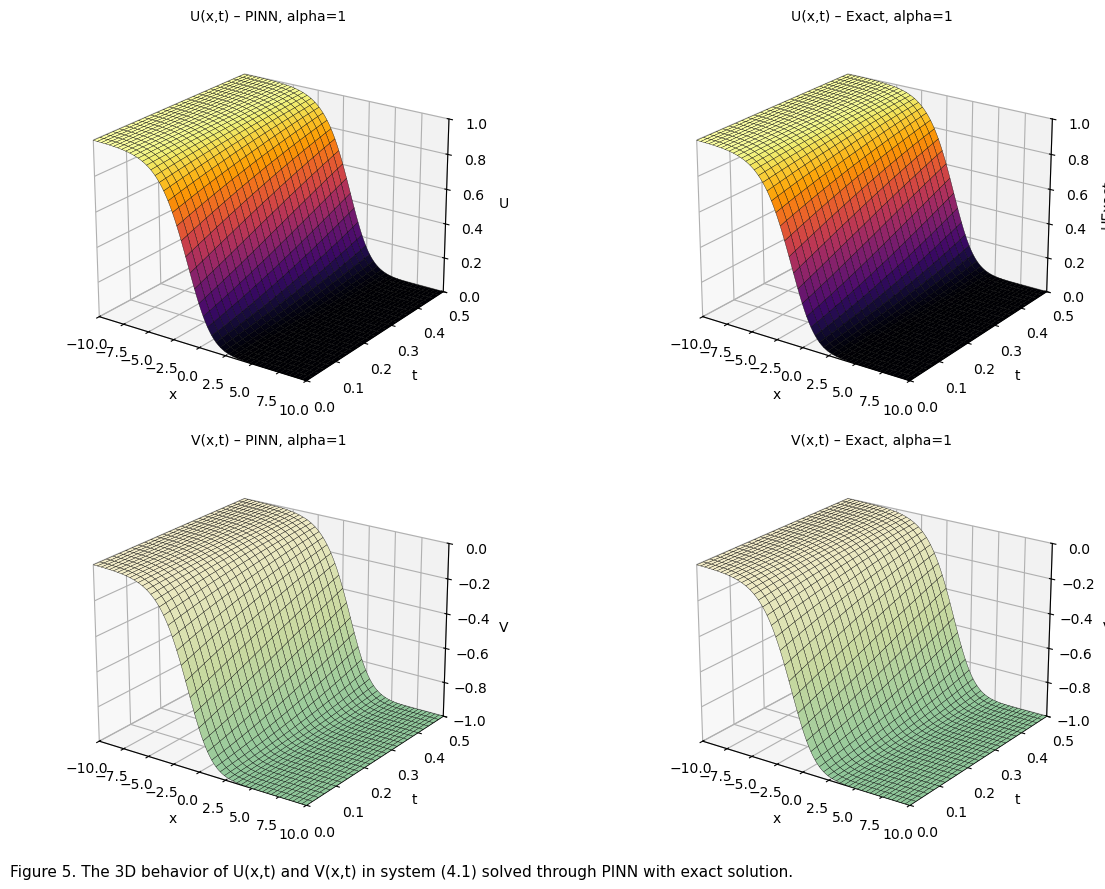

In [7]:
# ============================ 7) الرسم (1): الشكل 5 — سطوح ثلاثية الأبعاد، α=1 ============================
cmapU = "inferno"
cmapV = LinearSegmentedColormap.from_list("V", ["#8fc79a", "#c9d9a0", "#f3ecc8"])
Up, Vp = pinn[1.0]

fig = plt.figure(figsize=(14, 9))
panels = [(Up, "U(x,t) – PINN, alpha=1", cmapU, (0, 1), "U"), (U_ex, "U(x,t) – Exact, alpha=1", cmapU, (0, 1), "UExact"),
          (Vp, "V(x,t) – PINN, alpha=1", cmapV, (-1, 0), "V"), (V_ex, "V(x,t) – Exact, alpha=1", cmapV, (-1, 0), "V")]
for i, (Z, title, cm, zl, zlab) in enumerate(panels, 1):
    ax = fig.add_subplot(2, 2, i, projection="3d")
    ax.plot_surface(Xg, Tg, Z, cmap=cm, rstride=4, cstride=4, edgecolor="k", linewidth=0.25, antialiased=True)
    ax.set_title(title, fontsize=10); ax.set_xlabel("x"); ax.set_ylabel("t"); ax.set_zlabel(zlab)
    ax.set_xlim(-10, 10); ax.set_ylim(0, 0.5); ax.set_zlim(*zl); ax.view_init(elev=22, azim=-55)
fig.text(0.1, 0.02, "Figure 5. The 3D behavior of U(x,t) and V(x,t) in system (4.1) solved through PINN with exact solution.", fontsize=11)
plt.tight_layout(rect=[0, 0.04, 1, 1]); plt.savefig("figures/fig5_3d.png", dpi=200); plt.show()

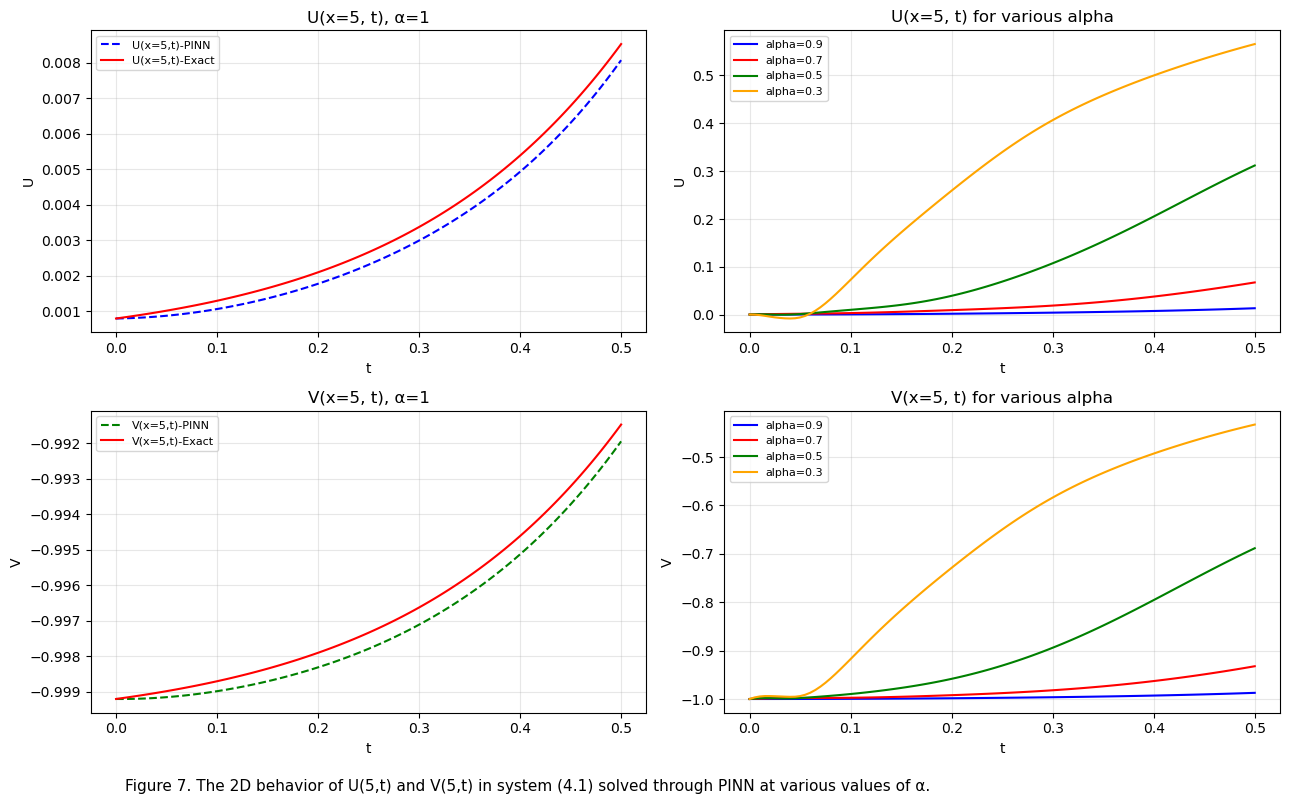

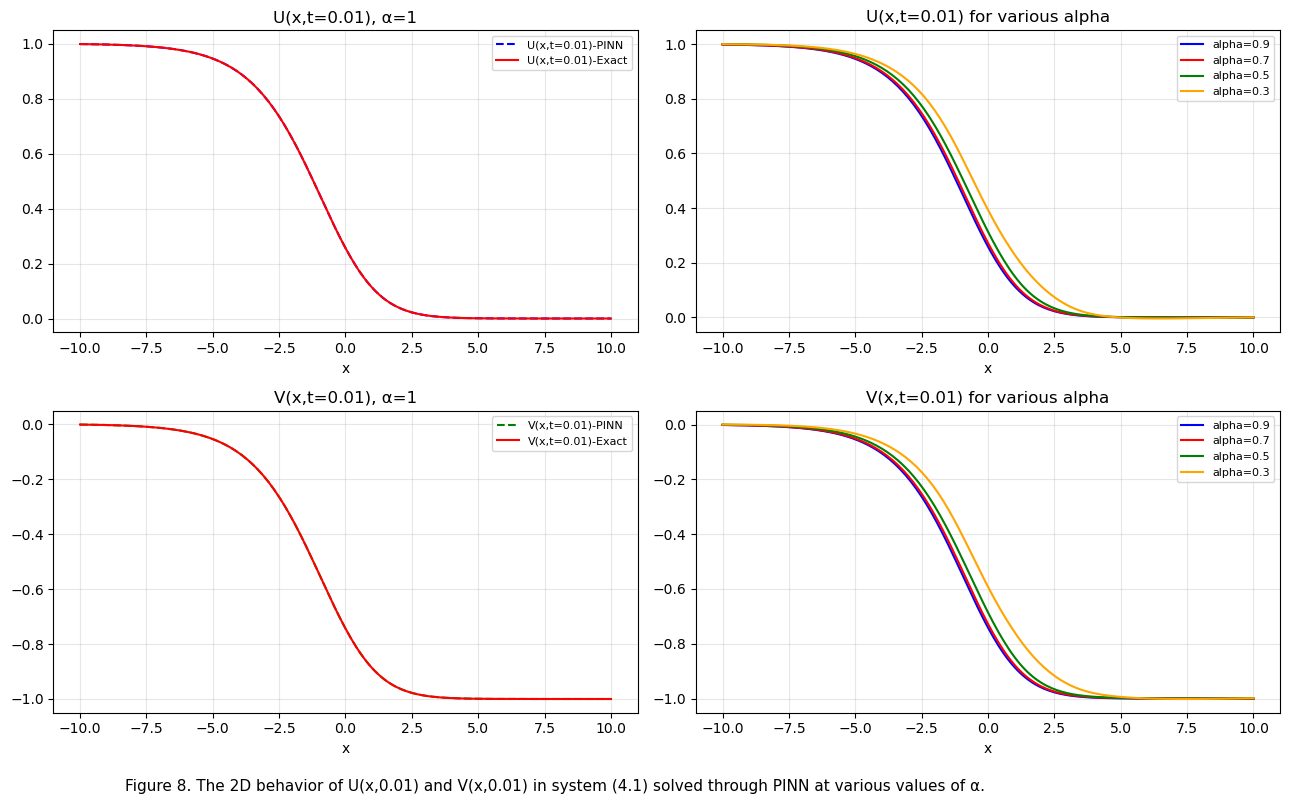

In [8]:
# ============================ 8) الرسم (2): الشكل 7 — U(5,t) و V(5,t) ============================
ix = np.argmin(np.abs(xs-5.0)); acol = {0.9: "blue", 0.7: "red", 0.5: "green", 0.3: "orange"}
fig, axs = plt.subplots(2, 2, figsize=(13, 8))
axs[0,0].plot(ts, pinn[1.0][0][ix], "b--", label="U(x=5,t)-PINN"); axs[0,0].plot(ts, U_ex[ix], "r-", label="U(x=5,t)-Exact")
axs[1,0].plot(ts, pinn[1.0][1][ix], "g--", label="V(x=5,t)-PINN"); axs[1,0].plot(ts, V_ex[ix], "r-", label="V(x=5,t)-Exact")
for a in ALPHAS:
    axs[0,1].plot(ts, pinn[a][0][ix], color=acol[a], label=f"alpha={a}")
    axs[1,1].plot(ts, pinn[a][1][ix], color=acol[a], label=f"alpha={a}")
axs[0,0].set_title("U(x=5, t), α=1"); axs[1,0].set_title("V(x=5, t), α=1")
axs[0,1].set_title("U(x=5, t) for various alpha"); axs[1,1].set_title("V(x=5, t) for various alpha")
for ax in axs.ravel(): ax.set_xlabel("t"); ax.grid(alpha=.3); ax.legend(fontsize=8)
axs[0,0].set_ylabel("U"); axs[1,0].set_ylabel("V"); axs[0,1].set_ylabel("U"); axs[1,1].set_ylabel("V")
fig.text(0.1, 0.005, "Figure 7. The 2D behavior of U(5,t) and V(5,t) in system (4.1) solved through PINN at various values of α.", fontsize=11)
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.savefig("figures/fig7_x5.png", dpi=200); plt.show()

# ============================ 9) الرسم (3): الشكل 8 — U(x,0.01) و V(x,0.01) ============================
it = np.argmin(np.abs(ts-0.01))
fig, axs = plt.subplots(2, 2, figsize=(13, 8))
axs[0,0].plot(xs, pinn[1.0][0][:, it], "b--", label="U(x,t=0.01)-PINN"); axs[0,0].plot(xs, U_ex[:, it], "r-", label="U(x,t=0.01)-Exact")
axs[1,0].plot(xs, pinn[1.0][1][:, it], "g--", label="V(x,t=0.01)-PINN"); axs[1,0].plot(xs, V_ex[:, it], "r-", label="V(x,t=0.01)-Exact")
for a in ALPHAS:
    axs[0,1].plot(xs, pinn[a][0][:, it], color=acol[a], label=f"alpha={a}")
    axs[1,1].plot(xs, pinn[a][1][:, it], color=acol[a], label=f"alpha={a}")
axs[0,0].set_title("U(x,t=0.01), α=1"); axs[1,0].set_title("V(x,t=0.01), α=1")
axs[0,1].set_title("U(x,t=0.01) for various alpha"); axs[1,1].set_title("V(x,t=0.01) for various alpha")
for ax in axs.ravel(): ax.set_xlabel("x"); ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.text(0.1, 0.005, "Figure 8. The 2D behavior of U(x,0.01) and V(x,0.01) in system (4.1) solved through PINN at various values of α.", fontsize=11)
plt.tight_layout(rect=[0, 0.03, 1, 1]); plt.savefig("figures/fig8_t001.png", dpi=200); plt.show()

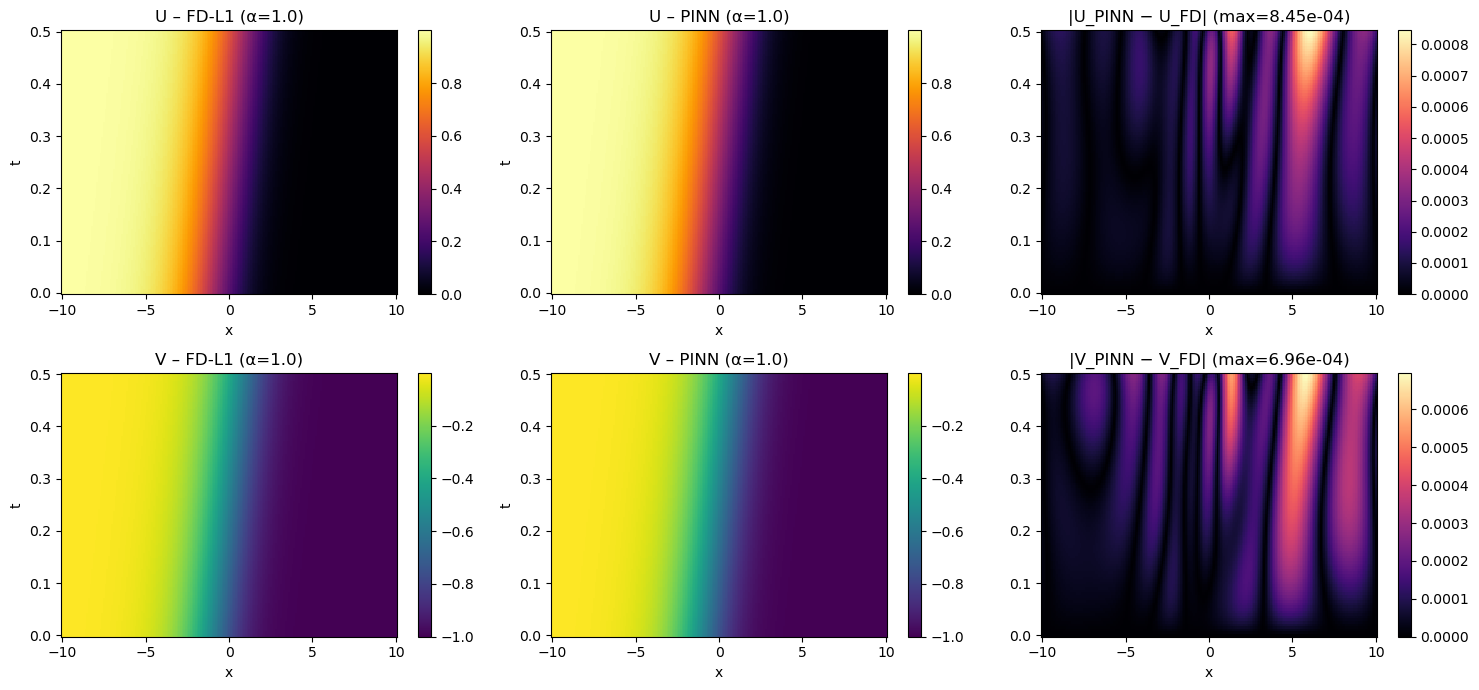

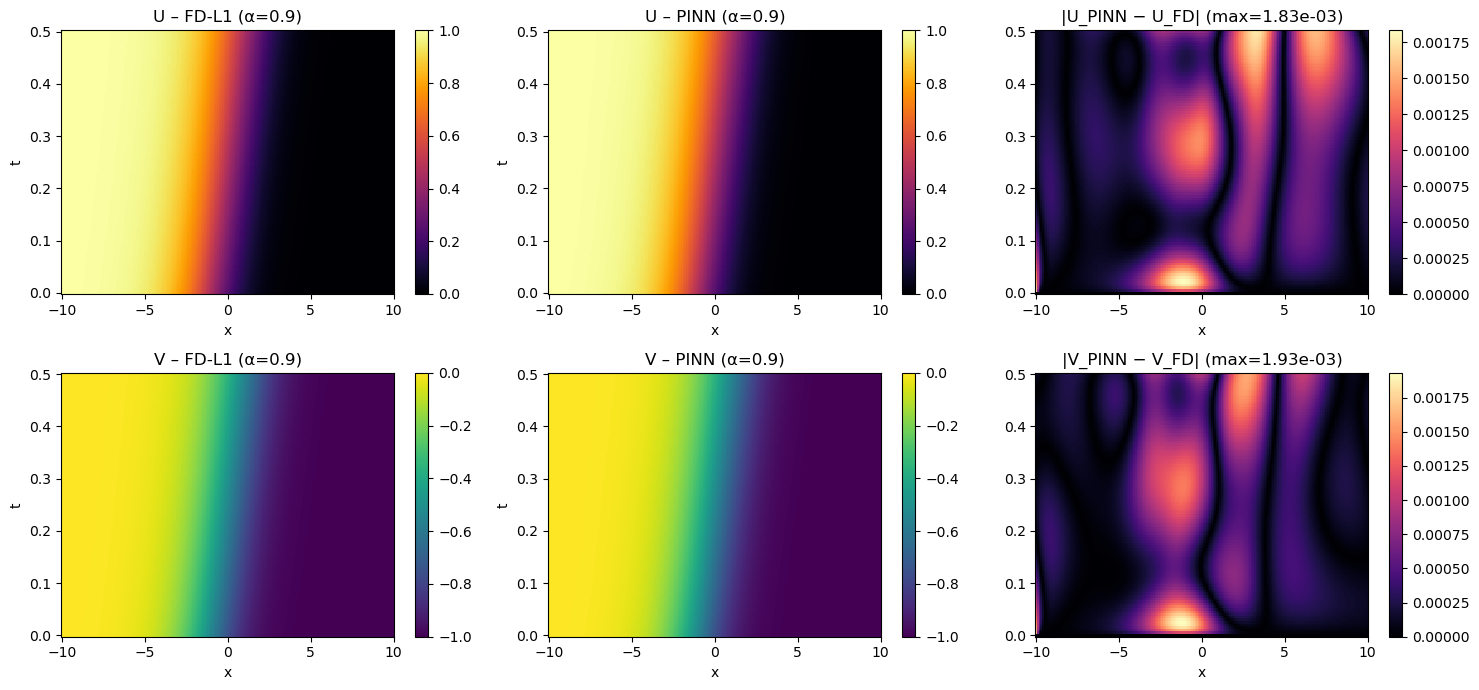

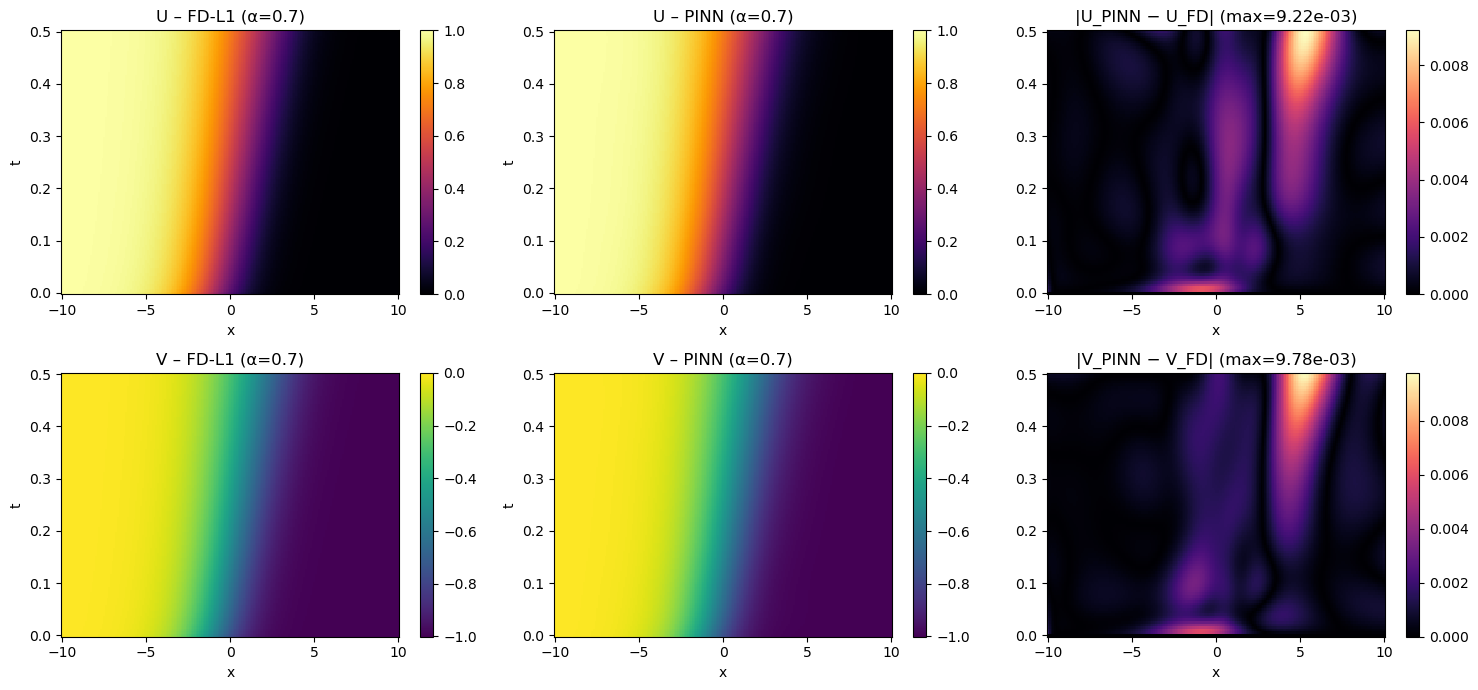

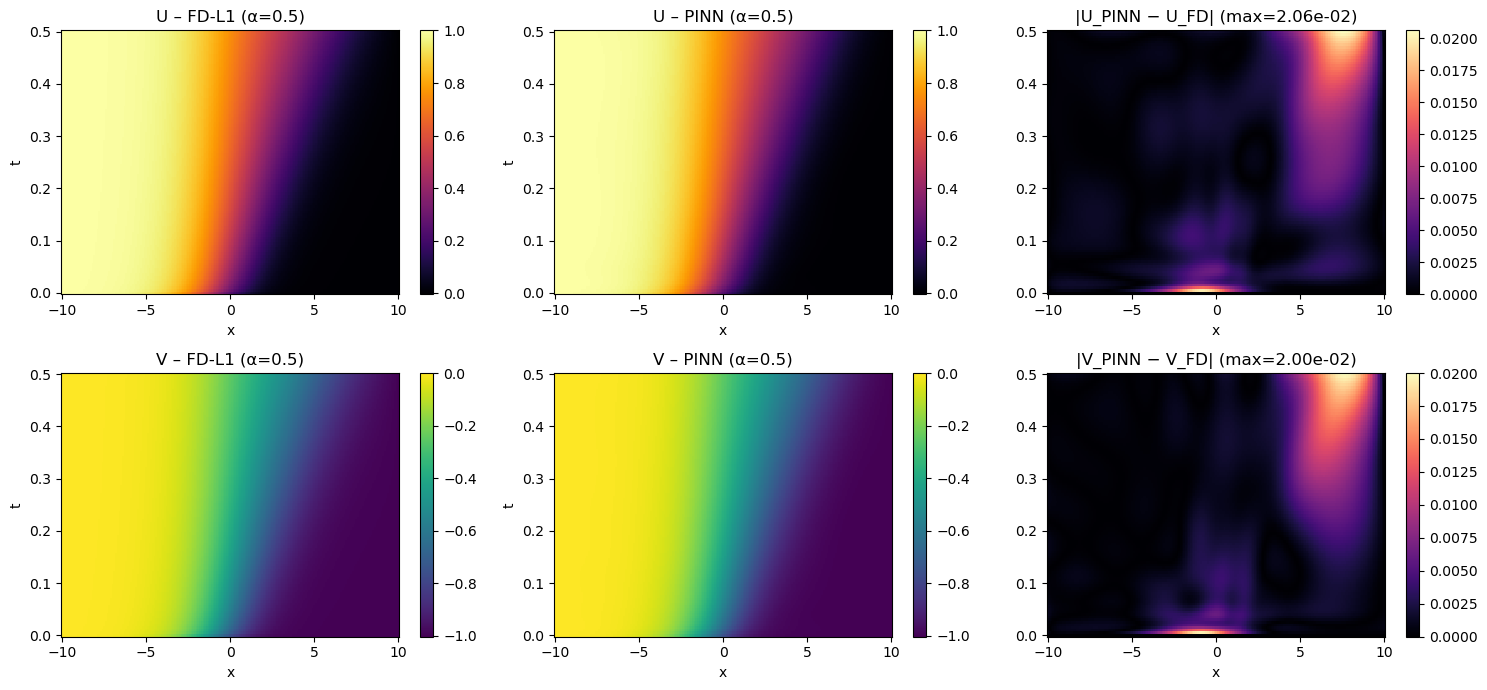

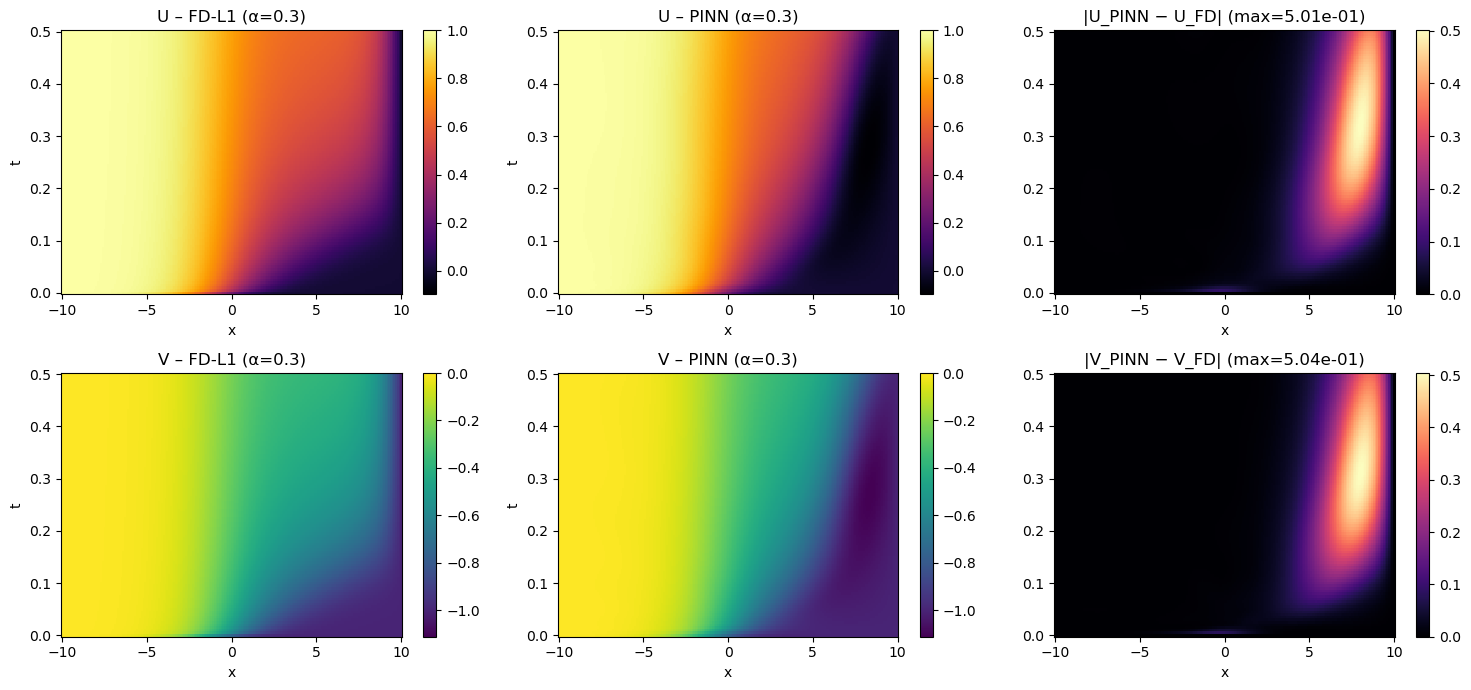

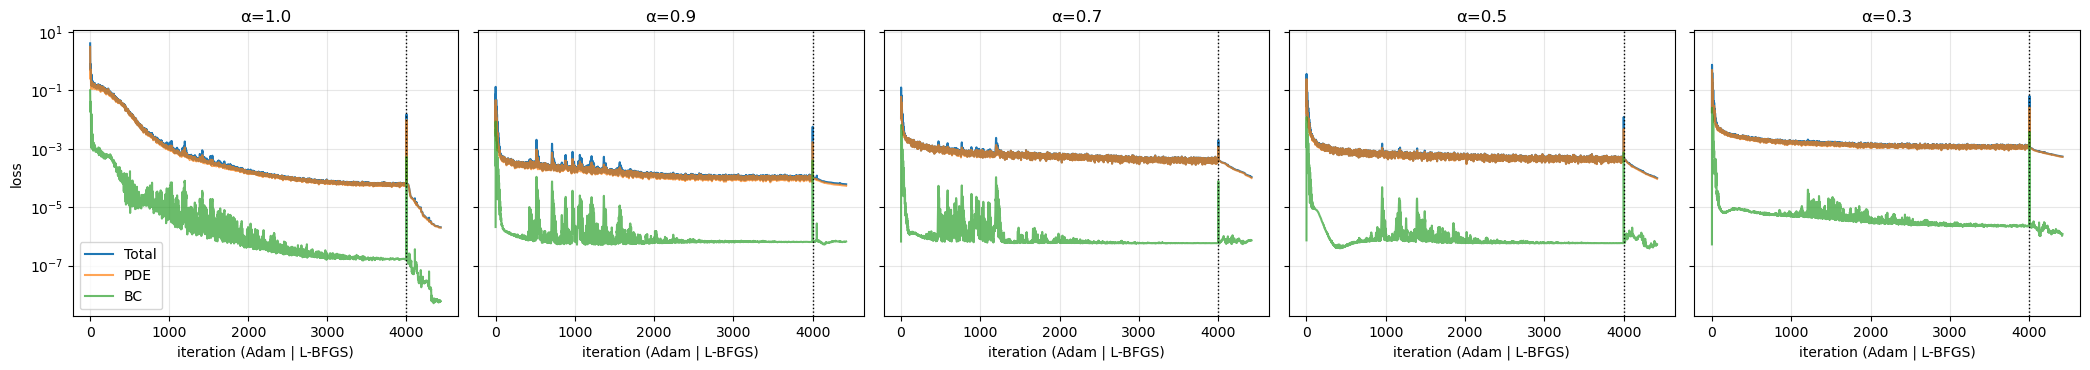

In [9]:
# ============================ 10) رسوم المقارنة (PINN مقابل العددي) والخطأ المطلق ============================
for a in [1.0] + ALPHAS:
    fig, axs = plt.subplots(2, 3, figsize=(15, 7))
    for r, (name, k) in enumerate((("U", 0), ("V", 1))):
        P, R = pinn[a][k], ref[a][k]; vmin, vmax = min(P.min(), R.min()), max(P.max(), R.max())
        for c_, (Z, ttl) in enumerate(((R, f"{name} – FD-L1 (α={a})"), (P, f"{name} – PINN (α={a})"))):
            im = axs[r, c_].pcolormesh(Xg, Tg, Z, shading="auto", vmin=vmin, vmax=vmax, cmap="inferno" if k == 0 else "viridis")
            axs[r, c_].set_title(ttl); axs[r, c_].set_xlabel("x"); axs[r, c_].set_ylabel("t"); plt.colorbar(im, ax=axs[r, c_])
        im = axs[r, 2].pcolormesh(Xg, Tg, np.abs(P-R), shading="auto", cmap="magma")
        axs[r, 2].set_title(f"|{name}_PINN − {name}_FD| (max={np.abs(P-R).max():.2e})"); axs[r, 2].set_xlabel("x"); plt.colorbar(im, ax=axs[r, 2])
    plt.tight_layout(); plt.savefig(f"figures/compare_alpha_{a}.png", dpi=150); plt.show()

# ---- منحنيات تقارب الخسارة ----
fig, axs = plt.subplots(1, len(hists), figsize=(4.2*len(hists), 3.8), sharey=True)
for ax, (a, h) in zip(np.atleast_1d(axs), hists.items()):
    ax.semilogy(h["total"], label="Total"); ax.semilogy(h["pde"], label="PDE", alpha=.7); ax.semilogy(h["bc"], label="BC", alpha=.7)
    n_adam = int(np.sum(np.array(h["stage"]) == 0)); ax.axvline(n_adam, color="k", ls=":", lw=1)
    ax.set_title(f"α={a}"); ax.set_xlabel("iteration (Adam | L-BFGS)"); ax.grid(alpha=.3)
np.atleast_1d(axs)[0].set_ylabel("loss"); np.atleast_1d(axs)[0].legend()
plt.tight_layout(); plt.savefig("figures/loss_history.png", dpi=200); plt.show()

## ملاحظات ختامية (مزايا وعيوب)

| | PINN (fPINN + L1) | الطريقة العددية (FD-L1 / TAM) |
|---|---|---|
| **المزايا** | حل مستمر وقابل للاشتقاق في (x,t)، لا يحتاج شبكة منظمة، يمكن دمج بيانات وتقدير معاملات (مسألة عكسية) | سريع جداً لهذه المسألة أحادية البعد، دقة ورتبة تقارب معروفة، لا يحتاج تدريب |
| **العيوب** | بطيء (دقائق مقابل ثوانٍ)، دقة عادةً 1e-3–1e-4 فقط، حساس لاختيار الأوزان والـ collocation، تكلفة الذاكرة في L1 تنمو مع $N_t^2$ | مرتبط بالشبكة، التاريخ الكامل مطلوب (ذاكرة $O(N_t N_x)$)، تعميم لمعاملات/شروط جديدة يتطلب إعادة الحل |